# Visualizations to Match Slide Presentation

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/Users/tanvirsingh/Downloads/BNPL_Financial_Default_Risk_Dataset.csv")

In [3]:
df = df.drop(columns="Customer_ID")

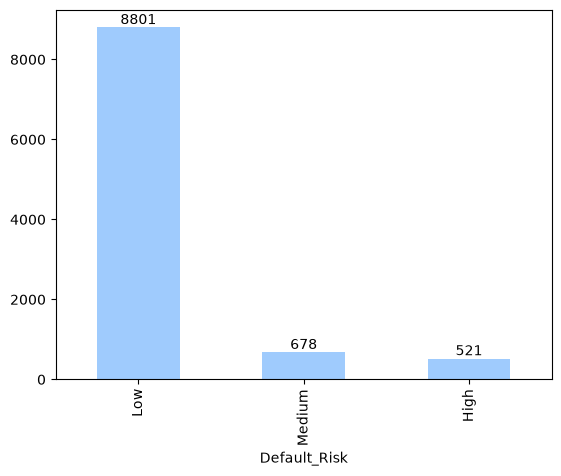

In [4]:
ax = df["Default_Risk"].value_counts().plot.bar(color="#9fcbfd")
ax.bar_label(ax.containers[0])
plt.show()

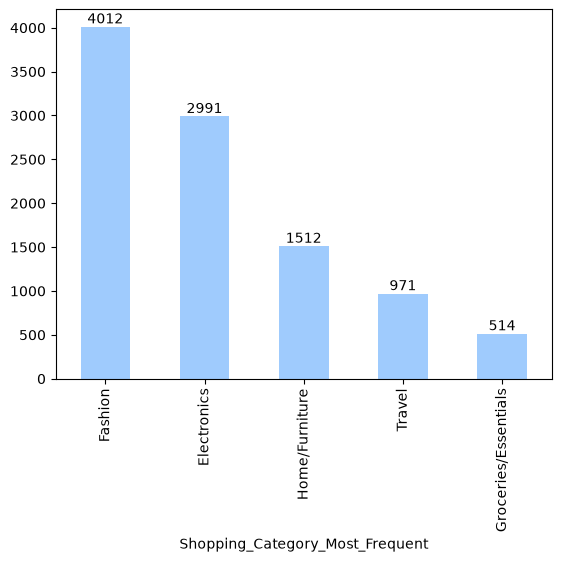

In [5]:
ax = df["Shopping_Category_Most_Frequent"].value_counts().plot.bar(color="#9fcbfd")
ax.bar_label(ax.containers[0])
plt.show()

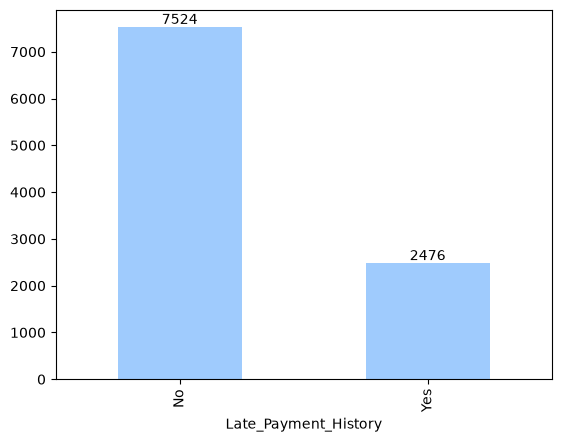

In [6]:
ax = df["Late_Payment_History"].value_counts().plot.bar(color="#9fcbfd")
ax.bar_label(ax.containers[0])
plt.show()

In [7]:
palette = {"Low": "#9fcbfd", "Medium": "#d2a6ed", "High": "#ffafa3"}

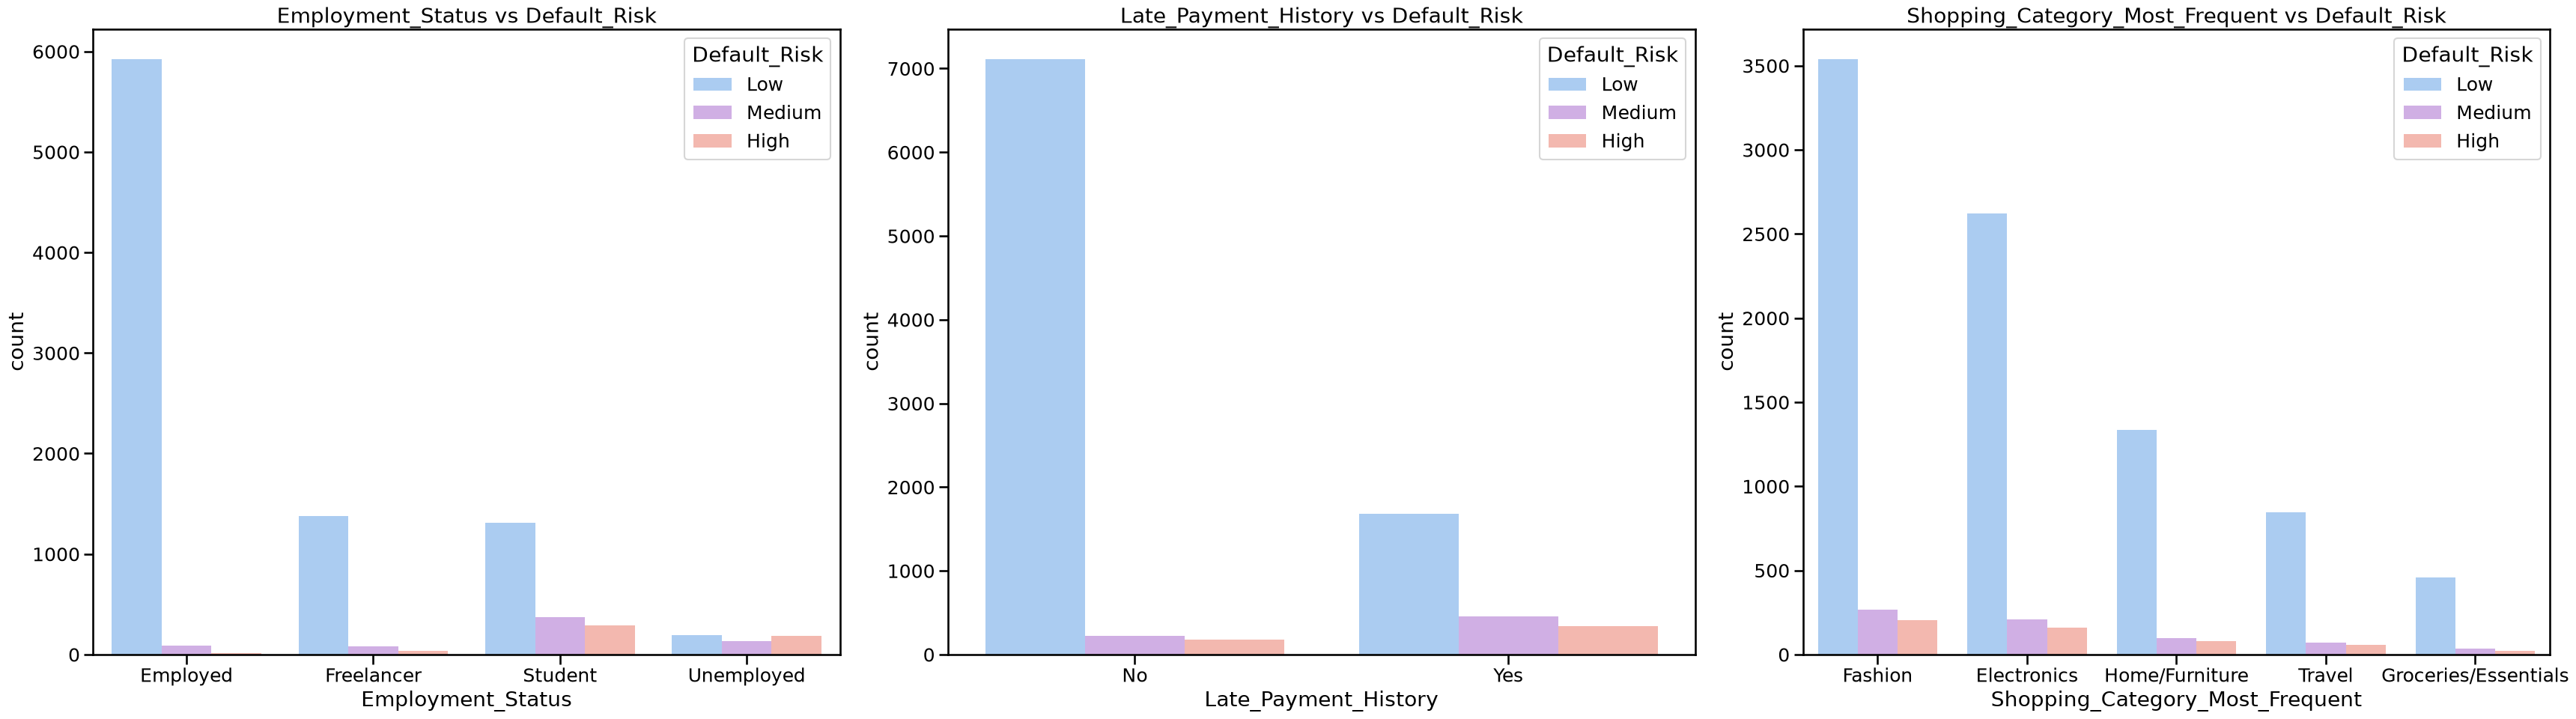

In [8]:
### Categorical features grouped by Default_Risk (discrete features)

categorical_features = ['Employment_Status','Late_Payment_History','Shopping_Category_Most_Frequent']

with sns.plotting_context("talk", font_scale=1.1):

    fig, axes = plt.subplots(1, 3, figsize=(35, 10))
    axes = axes.flatten()

    for i, col in enumerate(categorical_features):
        sns.countplot(data=df, x=col, hue='Default_Risk',palette=palette, ax=axes[i])
        axes[i].set_title(f"{col} vs Default_Risk")

    plt.tight_layout()
    plt.show() 


<Axes: >

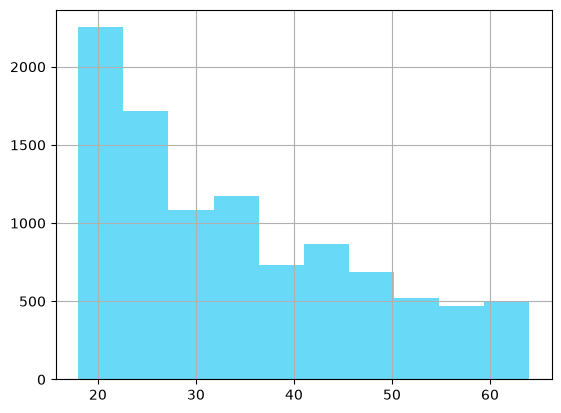

In [9]:
df["Age"].hist(color = "#68daf8")

<Axes: >

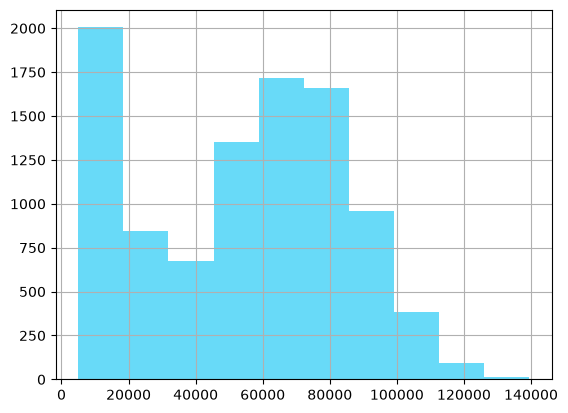

In [10]:
df["Income_USD"].hist(color = "#68daf8")

<Axes: >

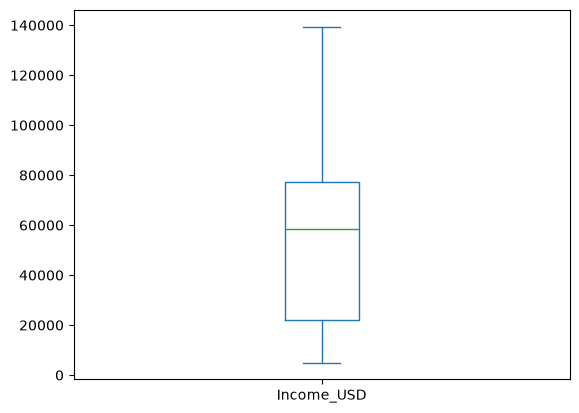

In [11]:
df["Income_USD"].plot.box()

<Axes: >

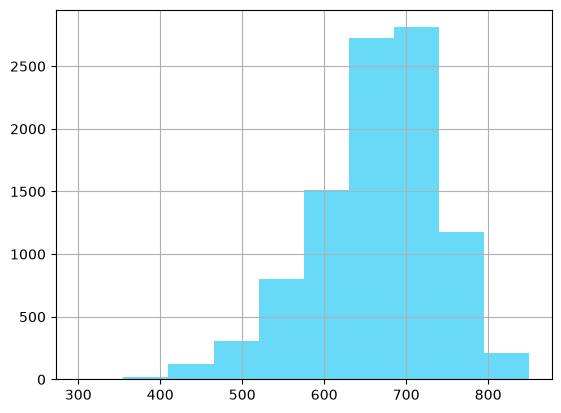

In [12]:
df["Credit_Score"].hist(color = "#68daf8")

<Axes: >

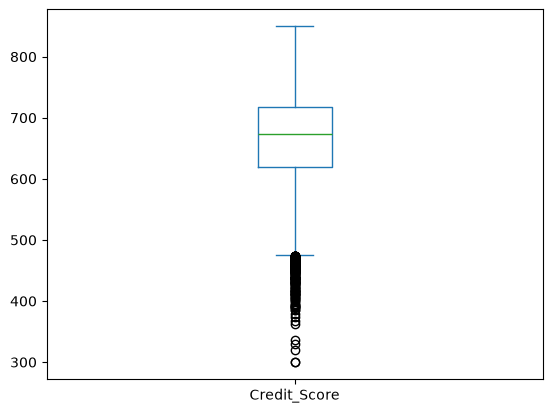

In [13]:
df["Credit_Score"].plot.box()

<Axes: >

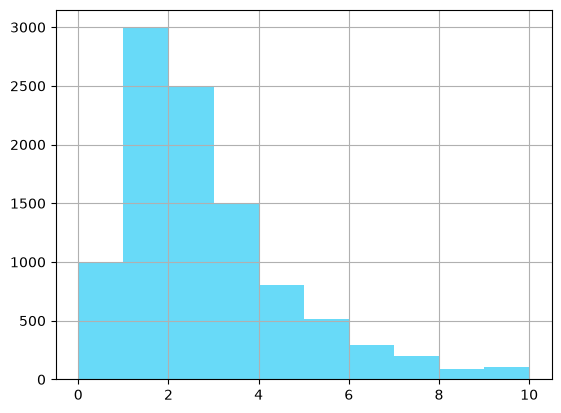

In [14]:
df["Total_BNPL_Active_Loans"].hist(color = "#68daf8")

<Axes: >

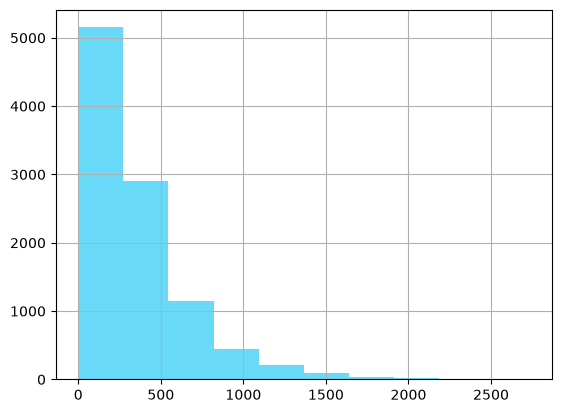

In [15]:
df["Total_BNPL_Debt_USD"].hist(color = "#68daf8")

<Axes: >

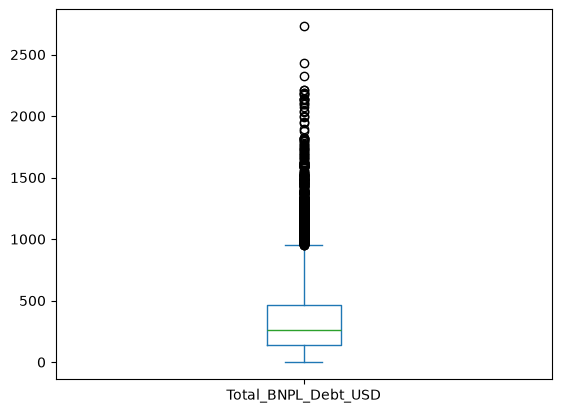

In [16]:
df["Total_BNPL_Debt_USD"].plot.box()

The distribution of Total Debt is heavily Left Skewed, Favoring those with low to no debt

<Axes: >

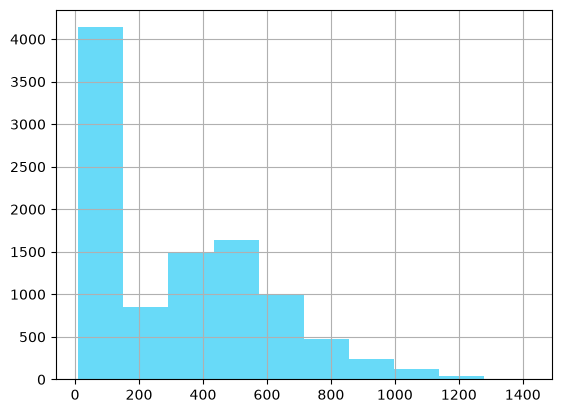

In [17]:
df["Average_Transaction_Value_USD"].hist(color = "#68daf8")

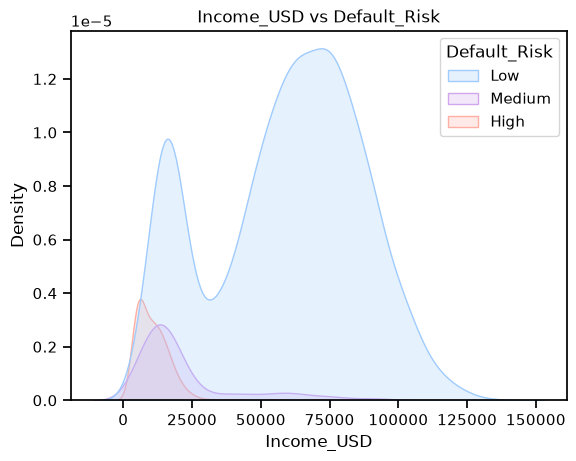

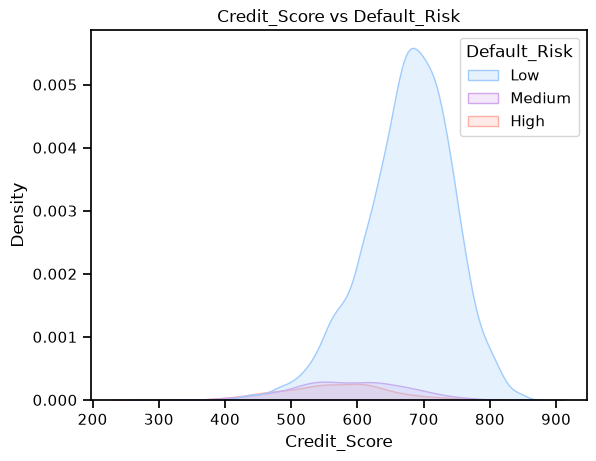

In [18]:
### Highest correlated features grouped by Default_Risk (continuous features)

with sns.plotting_context("notebook", font_scale=1):

#  Income_USD & Default_Risk
    sns.kdeplot(data=df, x='Income_USD', hue='Default_Risk',palette=palette, fill=True)
    plt.title("Income_USD vs Default_Risk")
    plt.show()

# Credit_Score & Default_Risk
    sns.kdeplot(data=df, x='Credit_Score', hue='Default_Risk', palette=palette, fill=True)
    plt.title("Credit_Score vs Default_Risk")
    plt.show()

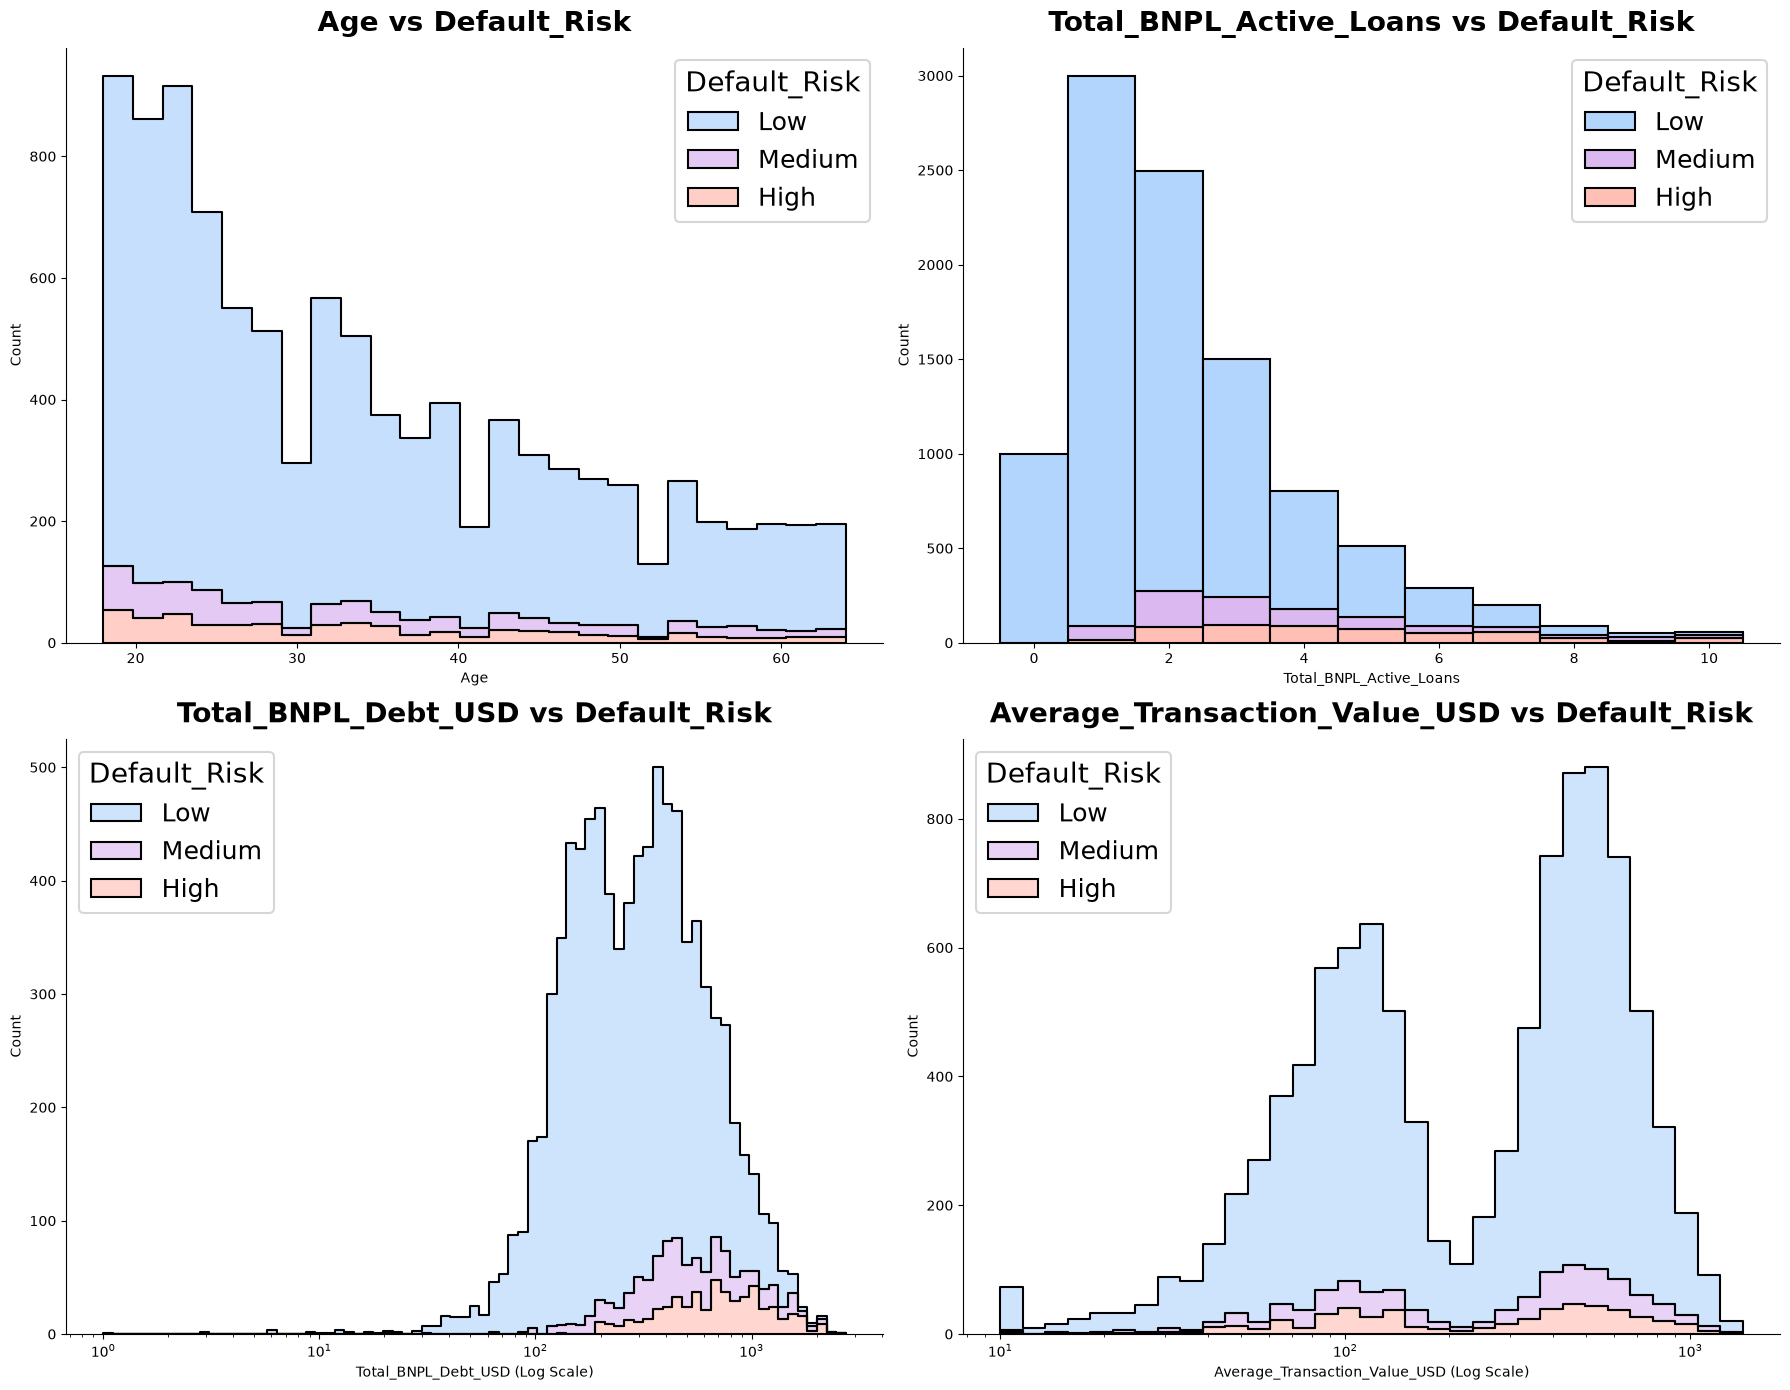

In [19]:
### Numerical features grouped by Default_Risk (integer features)

numerical_features = ['Age', 'Total_BNPL_Active_Loans', 'Total_BNPL_Debt_USD', 'Average_Transaction_Value_USD']

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

with sns.plotting_context('talk', font_scale=1.1):
    for i, col in enumerate(numerical_features):
        
        if col == 'Total_BNPL_Active_Loans':
            sns.histplot(
                data=df, x=col, hue="Default_Risk", palette=palette,
                discrete=True, multiple="stack", alpha=0.8, ax=axes[i]
            )
            
        elif 'USD' in col or 'Value' in col:
            sns.histplot(
                data=df[df[col] > 0], x=col, hue="Default_Risk", palette=palette,
                log_scale=(True, False), element="step", multiple="stack", alpha=0.5, ax=axes[i]
            )
            axes[i].set_xlabel(f"{col} (Log Scale)")
            
        else:
            sns.histplot(
                data=df, x=col, hue="Default_Risk", palette=palette,
                multiple="stack", element="step", alpha=0.6, ax=axes[i]
            )
            
        axes[i].set_title(f"{col} vs Default_Risk", fontweight='bold', pad=12)
        sns.despine(ax=axes[i])

plt.tight_layout()
plt.show()
